# (اسم المشروع- يحتاج نغيره اذا اعتمدنا الاسم) تأمينك
## Deep Learning project

##### Dataset link: https://data.mendeley.com/datasets/5cxyb5fp4f/2$0
## Team members:
* Tarfah Alsunaidi
* Razan
* Aleen
* Layan

## Libraries

In [2]:
%pip install tensorflow keras-tuner

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install tensorboard

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import regularizers
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import keras_tuner as kt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

## Dataset import

In [5]:
DATA_PATH = 'Motor vehicle insurance data.csv'

df = pd.read_csv(DATA_PATH, sep=';')
display(df.head())
print("Shape:",df.shape)

,ID,Date_start_contract,Date_last_renewal,Date_next_renewal,Date_birth,Date_driving_licence,Distribution_channel,Seniority,Policies_in_force,Max_policies,...,Area,Second_driver,Year_matriculation,Power,Cylinder_capacity,Value_vehicle,N_doors,Type_fuel,Length,Weight
0,1,05/11/2015,05/11/2015,05/11/2016,15/04/1956,20/03/1976,0,4,1,2,...,0,0,2004,80,599,7068.0,0,P,NaN,190
1,1,05/11/2015,05/11/2016,05/11/2017,15/04/1956,20/03/1976,0,4,1,2,...,0,0,2004,80,599,7068.0,0,P,NaN,190
2,1,05/11/2015,05/11/2017,05/11/2018,15/04/1956,20/03/1976,0,4,2,2,...,0,0,2004,80,599,7068.0,0,P,NaN,190
3,1,05/11/2015,05/11/2018,05/11/2019,15/04/1956,20/03/1976,0,4,2,2,...,0,0,2004,80,599,7068.0,0,P,NaN,190
4,2,26/09/2017,26/09/2017,26/09/2018,15/04/1956,20/03/1976,0,4,2,2,...,0,0,2004,80,599,7068.0,0,P,NaN,190


Shape: (105555, 30)


## Data preprocessing

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105555 entries, 0 to 105554
Data columns (total 30 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   ID                    105555 non-null  int64  
 1   Date_start_contract   105555 non-null  object 
 2   Date_last_renewal     105555 non-null  object 
 3   Date_next_renewal     105555 non-null  object 
 4   Date_birth            105555 non-null  object 
 5   Date_driving_licence  105555 non-null  object 
 6   Distribution_channel  105555 non-null  int64  
 7   Seniority             105555 non-null  int64  
 8   Policies_in_force     105555 non-null  int64  
 9   Max_policies          105555 non-null  int64  
 10  Max_products          105555 non-null  int64  
 11  Lapse                 105555 non-null  int64  
 12  Date_lapse            35147 non-null   object 
 13  Payment               105555 non-null  int64  
 14  Premium               105555 non-null  float64
 15  

In [7]:
df.describe()

,ID,Distribution_channel,Seniority,Policies_in_force,Max_policies,Max_products,Lapse,Payment,Premium,Cost_claims_year,...,Type_risk,Area,Second_driver,Year_matriculation,Power,Cylinder_capacity,Value_vehicle,N_doors,Length,Weight
count,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,...,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,95226.000000,105555.000000
mean,26271.286789,0.451310,6.696604,1.455649,1.837232,1.065842,0.221837,0.319180,315.892557,153.557305,...,2.721804,0.273895,0.123708,2004.728038,92.682611,1617.759367,18413.657243,4.067898,4.252007,1191.262422
std,15388.309324,0.497626,6.263911,0.928427,1.155536,0.267807,0.464858,0.466161,140.927969,1477.112362,...,0.614835,0.445958,0.329250,6.767037,37.012645,604.697382,9135.074235,1.511839,0.393220,458.081834
min,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,40.140000,0.000000,...,1.000000,0.000000,0.000000,1950.000000,0.000000,49.000000,270.460000,0.000000,1.978000,43.000000
25%,12925.000000,0.000000,3.000000,1.000000,1.000000,1.000000,0.000000,0.000000,241.610000,0.000000,...,3.000000,0.000000,0.000000,2001.000000,75.000000,1390.000000,13127.210000,3.000000,3.999000,1043.000000
50%,26082.000000,0.000000,4.000000,1.000000,2.000000,1.000000,0.000000,0.000000,292.280000,0.000000,...,3.000000,0.000000,0.000000,2005.000000,90.000000,1598.000000,17608.770000,5.000000,4.230000,1205.000000
75%,39754.000000,1.000000,9.000000,2.000000,2.000000,1.000000,0.000000,1.000000,361.640000,0.000000,...,3.000000,1.000000,0.000000,2008.000000,110.000000,1910.000000,22595.000000,5.000000,4.443000,1388.000000
max,53502.000000,1.000000,40.000000,17.000000,17.000000,4.000000,7.000000,1.000000,2993.340000,260853.240000,...,4.000000,1.000000,1.000000,2018.000000,580.000000,7480.000000,220675.800000,6.000000,8.218000,7300.000000


### 1. Missing values

In [8]:
df.isnull().sum()

ID                          0
Date_start_contract         0
Date_last_renewal           0
Date_next_renewal           0
Date_birth                  0
Date_driving_licence        0
Distribution_channel        0
Seniority                   0
Policies_in_force           0
Max_policies                0
Max_products                0
Lapse                       0
Date_lapse              70408
Payment                     0
Premium                     0
Cost_claims_year            0
N_claims_year               0
N_claims_history            0
R_Claims_history            0
Type_risk                   0
Area                        0
Second_driver               0
Year_matriculation          0
Power                       0
Cylinder_capacity           0
Value_vehicle               0
N_doors                     0
Type_fuel                1764
Length                  10329
Weight                      0
dtype: int64

In [9]:
(df.isnull().sum()/len(df))*100

ID                       0.000000
Date_start_contract      0.000000
Date_last_renewal        0.000000
Date_next_renewal        0.000000
Date_birth               0.000000
Date_driving_licence     0.000000
Distribution_channel     0.000000
Seniority                0.000000
Policies_in_force        0.000000
Max_policies             0.000000
Max_products             0.000000
Lapse                    0.000000
Date_lapse              66.702667
Payment                  0.000000
Premium                  0.000000
Cost_claims_year         0.000000
N_claims_year            0.000000
N_claims_history         0.000000
R_Claims_history         0.000000
Type_risk                0.000000
Area                     0.000000
Second_driver            0.000000
Year_matriculation       0.000000
Power                    0.000000
Cylinder_capacity        0.000000
Value_vehicle            0.000000
N_doors                  0.000000
Type_fuel                1.671167
Length                   9.785420
Weight        

- Date_lapse is missing whenever the policy has not lapsed, it is informative not an error.
- Length is missing, impute with the median of the same type risk.
- Type_fuel is missing, will keep it as Unknown.

In [10]:
df['Length_missing'] = df['Length'].isna().astype(int)
df['Length'] = (df['Length']
                .fillna(df.groupby('Type_risk')['Length'].transform('median'))
                .fillna(df['Length'].median()))

In [11]:
df['Type_fuel'] = df['Type_fuel'].fillna('Unknown')

In [12]:
(df.isnull().sum()/len(df))*100

ID                       0.000000
Date_start_contract      0.000000
Date_last_renewal        0.000000
Date_next_renewal        0.000000
Date_birth               0.000000
Date_driving_licence     0.000000
Distribution_channel     0.000000
Seniority                0.000000
Policies_in_force        0.000000
Max_policies             0.000000
Max_products             0.000000
Lapse                    0.000000
Date_lapse              66.702667
Payment                  0.000000
Premium                  0.000000
Cost_claims_year         0.000000
N_claims_year            0.000000
N_claims_history         0.000000
R_Claims_history         0.000000
Type_risk                0.000000
Area                     0.000000
Second_driver            0.000000
Year_matriculation       0.000000
Power                    0.000000
Cylinder_capacity        0.000000
Value_vehicle            0.000000
N_doors                  0.000000
Type_fuel                0.000000
Length                   0.000000
Weight        

### 2. Change data type

In [13]:
date_cols = ['Date_start_contract', 'Date_last_renewal', 'Date_next_renewal',
             'Date_birth', 'Date_driving_licence', 'Date_lapse']

for c in date_cols:
    df[c] = pd.to_datetime(df[c], format='%d/%m/%Y', errors='coerce')

### 3. Invalid values

In [14]:
check = {
    'Power == 0':               df.Power == 0,
    'Cylinder_capacity < 50':   df.Cylinder_capacity < 50,
    'Weight < 100 kg':          df.Weight < 100,
    'N_doors == 0':             df.N_doors == 0,
}
display(pd.DataFrame({k: v.groupby(df.Type_risk).sum() for k, v in check.items()}).T
          .rename(columns={1: 'motorbike', 2: 'van', 3: 'car', 4: 'agricultural'}))
print('Power == 0 rows that also have unknown fuel:', ((df.Power == 0) & (df.Type_fuel == 'Unknown')).sum())

# Logical check
age_at_licence = (df.Date_driving_licence - df.Date_birth).dt.days / 365.25
print('\nLicence obtained before age 18:', (age_at_licence < 18).sum())
print('Vehicle registered after the renewal year:', (df.Year_matriculation > df.Date_last_renewal.dt.year).sum())
print('Claims cost > 0 but zero claims:', ((df.Cost_claims_year > 0) & (df.N_claims_year == 0)).sum())

Type_risk,motorbike,van,car,agricultural
Power == 0,1645,0,0,119
Cylinder_capacity < 50,2436,0,0,0
Weight < 100 kg,2833,0,0,0
N_doors == 0,8502,0,0,772


Power == 0 rows that also have unknown fuel: 1764

Licence obtained before age 18: 0
Vehicle registered after the renewal year: 0
Claims cost > 0 but zero claims: 0


- Power == 0 is physically impossible. Handle it as missing and impute with the median power of the same Type_risk.
- N_doors == 0 are all motorbikes/mopeds or agricultural vehicles so they are valid.

In [15]:
df['Power_missing'] = (df['Power'] == 0).astype(int)
df['Power'] = df['Power'].replace(0, np.nan)
df['Power'] = df['Power'].fillna(df.groupby('Type_risk')['Power'].transform('median'))

### 4. Feature engineering

In [16]:
date = df['Date_last_renewal']

df['Age']                 = ((date - df.Date_birth).dt.days / 365.25).round(1)
df['Driving_experience']  = ((date - df.Date_driving_licence).dt.days / 365.25).round(1)
df['Licence_age']         = ((df.Date_driving_licence - df.Date_birth).dt.days / 365.25).round(1)
df['Contract_years']      = ((date - df.Date_start_contract).dt.days / 365.25).round(1)
df['Vehicle_age']         = date.dt.year - df.Year_matriculation
df['Renewal_year']        = date.dt.year
df['Has_claim']           = (df.N_claims_year > 0).astype(int)

df['Vehicle_type'] = df.Type_risk.map({1: 'Motorbike', 2: 'Van', 3: 'Car', 4: 'Agricultural'})

df['Driving_experience'] = df['Driving_experience'].clip(lower=0)
df['Contract_years']     = df['Contract_years'].clip(lower=0)

### 5. Outliers

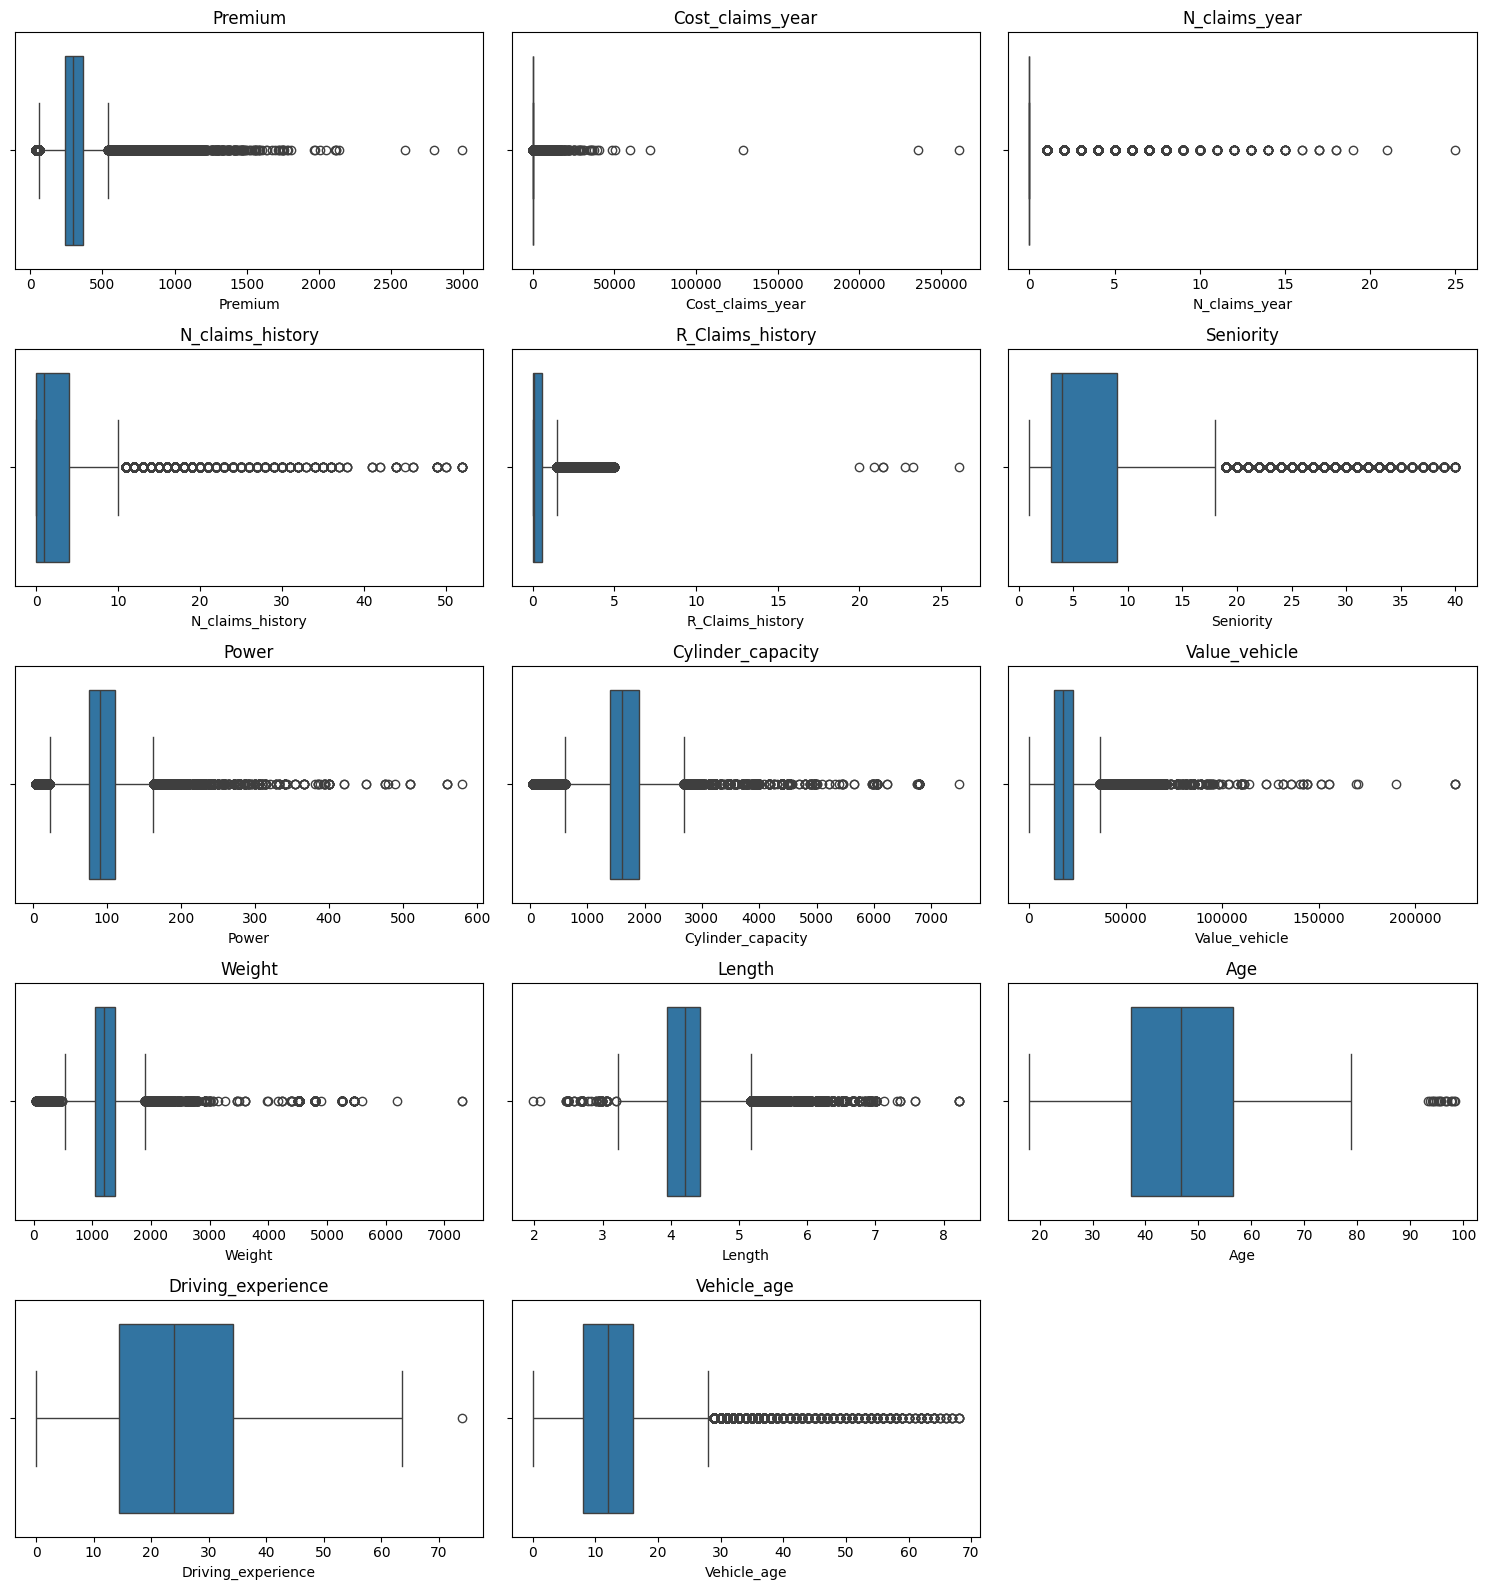

In [17]:
num_cols = ['Premium', 'Cost_claims_year', 'N_claims_year', 'N_claims_history', 'R_Claims_history',
            'Seniority', 'Power', 'Cylinder_capacity', 'Value_vehicle', 'Weight', 'Length',
            'Age', 'Driving_experience', 'Vehicle_age']

fig, axes = plt.subplots(5, 3, figsize=(15, 16))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
for ax in axes.ravel()[len(num_cols):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [18]:
#IQR Method
summary = []
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    summary.append([col, lower, upper, n_out, n_out / len(df) * 100])

outliers = pd.DataFrame(summary, columns=['column', 'lower', 'upper', 'n_outliers', '%'])
display(outliers)

,column,lower,upper,n_outliers,%
0,Premium,61.565,541.685,7381,6.992563
1,Cost_claims_year,0.000,0.000,19646,18.612098
2,N_claims_year,0.000,0.000,19646,18.612098
3,N_claims_history,-6.000,10.000,5013,4.749183
4,R_Claims_history,-0.885,1.475,8541,8.091516
5,Seniority,-6.000,18.000,7603,7.202880
6,Power,22.500,162.500,9572,9.068258
7,Cylinder_capacity,610.000,2690.000,10748,10.182369
8,Value_vehicle,-1074.475,36796.685,3344,3.168017
9,Weight,525.500,1905.500,11558,10.949742


In [19]:
#Remove Outliers
cols_to_clean = ['Premium', 'Value_vehicle', 'Age', 'Driving_experience', 'Length']

df_clean = df.copy()
for col in cols_to_clean:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df_clean = df_clean[(df_clean[col] >= lower) & (df_clean[col] <= upper)]

print('Before:', df.shape, ' After:', df_clean.shape)
print(f'Removed {len(df) - len(df_clean):,} rows ({(1 - len(df_clean)/len(df)):.1%})')

Before: (105555, 40)  After: (93401, 40)
Removed 12,154 rows (11.5%)


In [20]:
df_clean.to_csv('insurance_clean.csv', index=False)

## EDA

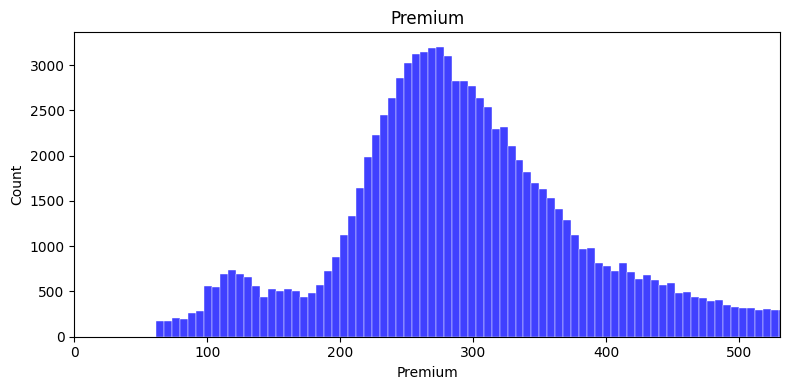

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df_clean.Premium, bins=80, ax=ax, color='blue', edgecolor='white', linewidth=0.3)
ax.set(title='Premium', xlabel='Premium', xlim=(0, df_clean.Premium.quantile(.995)))
plt.tight_layout()
plt.show()

Most premiums fall between €200 and €400 (median ≈ €284), with fewer policies at higher prices.

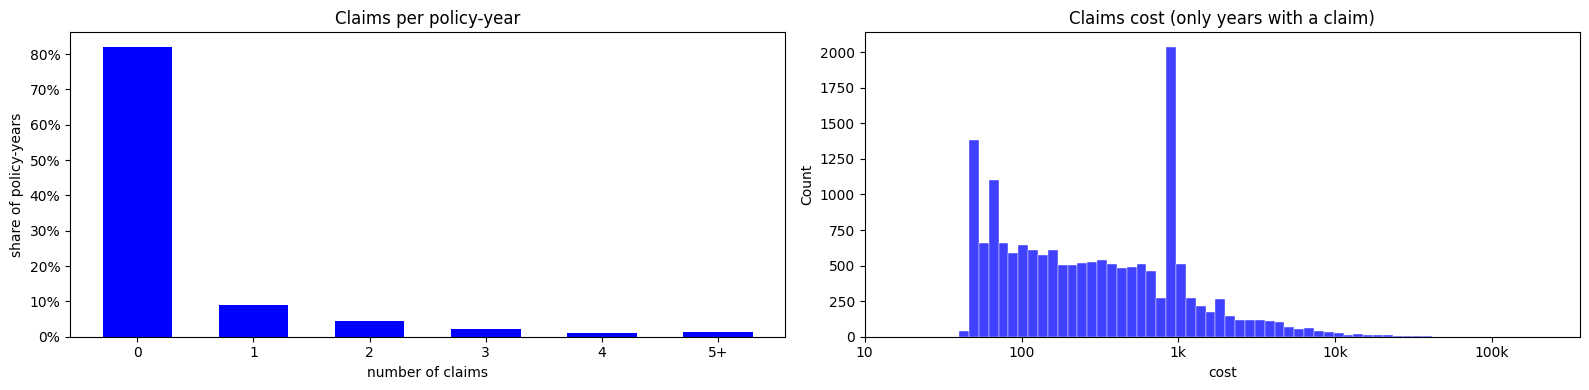

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))

claims = df_clean.N_claims_year.clip(upper=5).value_counts(normalize=True).sort_index()
claims.index = [str(i) if i < 5 else '5+' for i in claims.index]
ax[0].bar(claims.index, claims.values, color='blue', width=0.6)
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[0].set(title='Claims per policy-year', xlabel='number of claims', ylabel='share of policy-years')

pos = df_clean.loc[df_clean.Cost_claims_year > 0, 'Cost_claims_year']
sns.histplot(np.log10(pos), bins=60, ax=ax[1], color='blue', edgecolor='white', linewidth=0.3)
ax[1].set(title='Claims cost (only years with a claim)', xlabel='cost')
ax[1].set_xticks([1, 2, 3, 4, 5]); ax[1].set_xticklabels(['10', '100', '1k', '10k', '100k'])

plt.tight_layout()
plt.show()

- About 82% of policy-years have no claim, so claims are rare events.
- Most claims cost between €50 and €1,000, with a sharp spike near €900 that suggests a standard fixed payout.

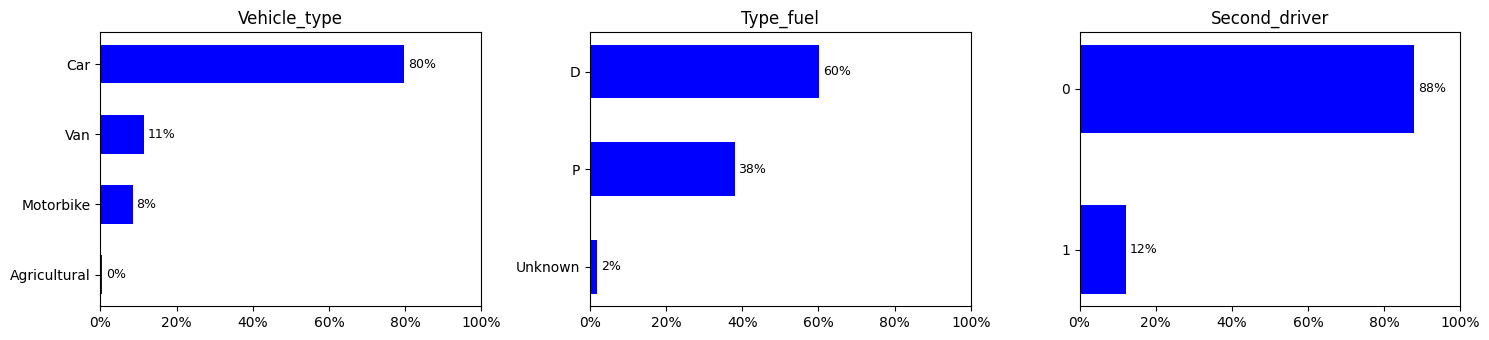

In [23]:
categorical_var = ['Vehicle_type', 'Type_fuel', 'Second_driver']
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, c in zip(axes.ravel(), categorical_var):
    vc = df_clean[c].value_counts(normalize=True)
    ax.barh(vc.index.astype(str), vc.values, color='blue', height=0.55)
    ax.invert_yaxis(); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
    for i, v in enumerate(vc.values): ax.text(v + .01, i, f'{v:.0%}', va='center', fontsize=9)
    ax.set(title=c, xlim=(0, 1))
plt.tight_layout()
plt.show()

The portfolio is mostly cars (80%), mostly diesel (60%), and usually has a single driver (88%).

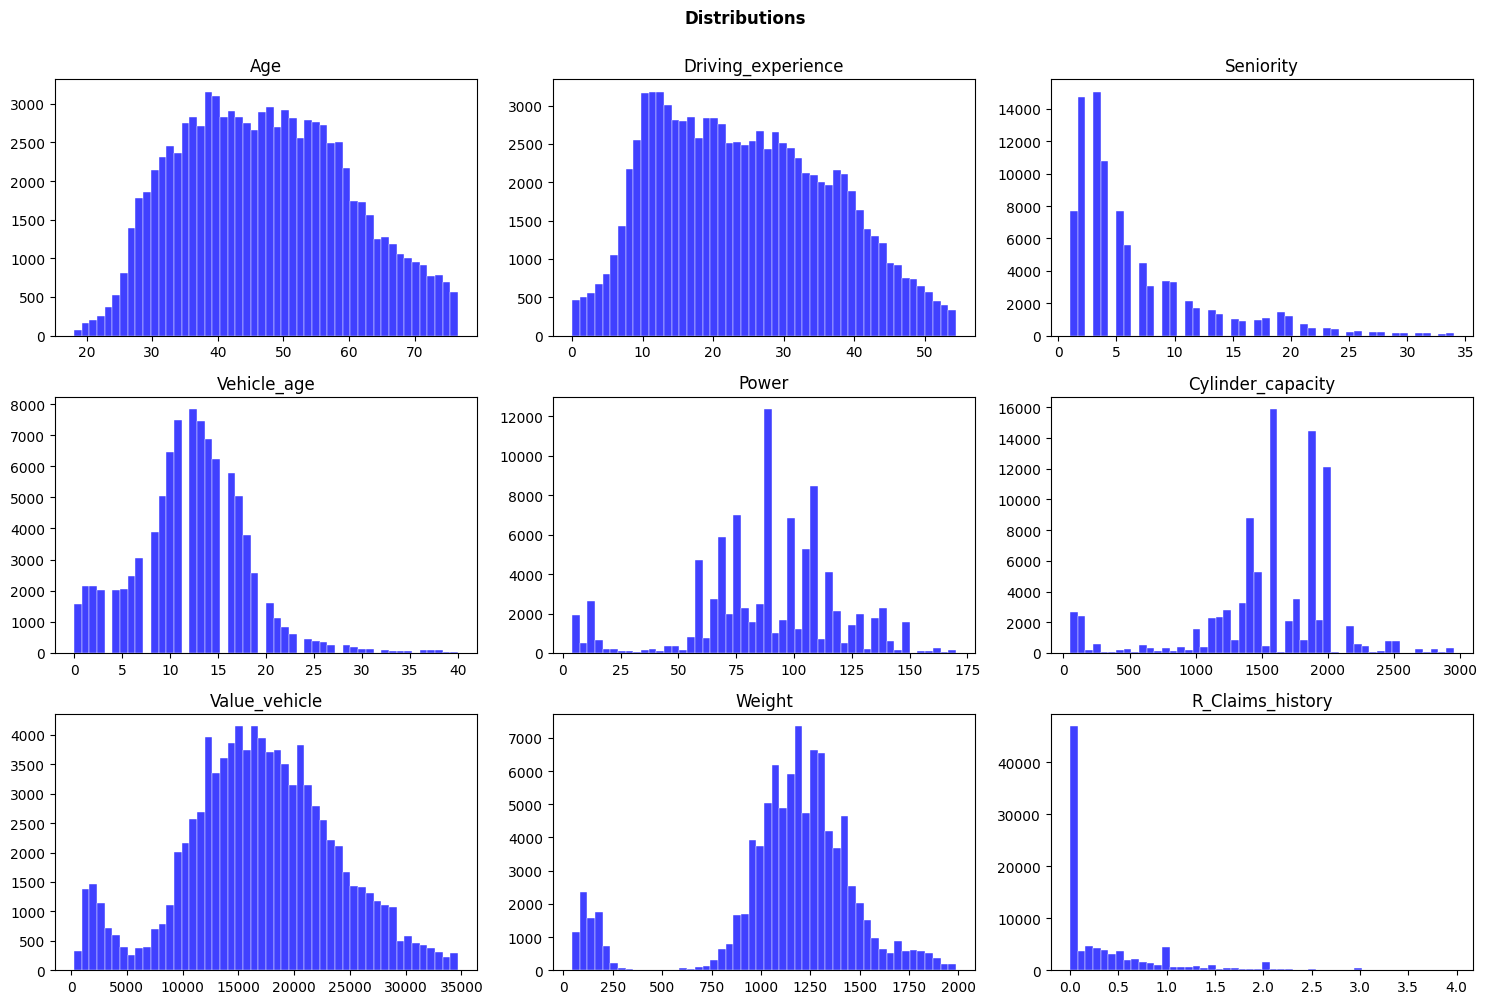

In [24]:
nums = ['Age', 'Driving_experience', 'Seniority', 'Vehicle_age', 'Power',
        'Cylinder_capacity', 'Value_vehicle', 'Weight', 'R_Claims_history']
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), nums):
    upper = df_clean[c].quantile(.995)
    sns.histplot(df_clean.loc[df_clean[c] <= upper, c], bins=50, ax=ax, color='blue', edgecolor='white', linewidth=0.3)
    ax.set(title=c, xlabel='', ylabel='')
fig.suptitle('Distributions', y=1.0, fontweight='bold')
plt.tight_layout(); plt.show()

Most drivers are 30–60 years old with 10–40 years of experience, and most vehicles are 8–17 years old and worth €10k–25k.

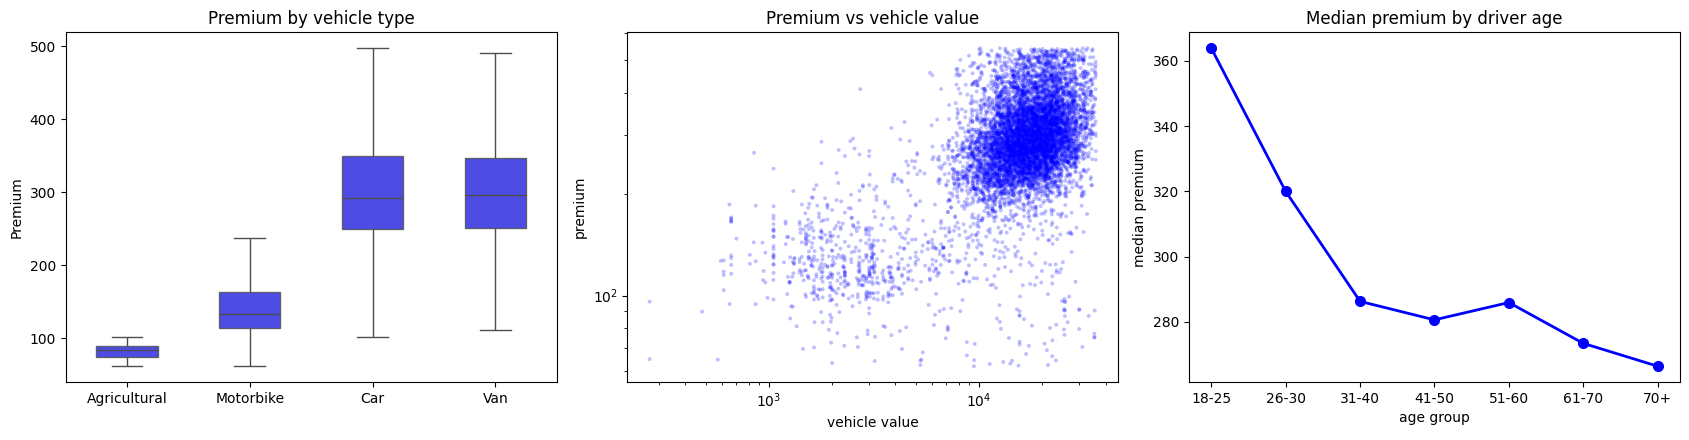

In [25]:
#what effect the premium
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
order = df_clean.groupby('Vehicle_type').Premium.median().sort_values().index
sns.boxplot(data=df_clean, x='Vehicle_type', y='Premium', order=order, ax=ax[0], color='blue',
            showfliers=False, width=.5, boxprops={'alpha': .8})
ax[0].set(title='Premium by vehicle type', xlabel='')

s = df_clean.sample(8000, random_state=0)
ax[1].scatter(s.Value_vehicle, s.Premium, s=8, alpha=.25, color='blue', edgecolor='none')
ax[1].set(xscale='log', yscale='log', title='Premium vs vehicle value',
          xlabel='vehicle value', ylabel='premium')

age_bins = pd.cut(df_clean.Age, [17, 25, 30, 40, 50, 60, 70, 100], labels=['18-25', '26-30', '31-40', '41-50', '51-60', '61-70', '70+'])
p = df_clean.groupby(age_bins, observed=True).Premium.median()
ax[2].plot(p.index.astype(str), p.values, marker='o', color='blue', lw=2, ms=7)
ax[2].set(title='Median premium by driver age', xlabel='age group', ylabel='median premium')
plt.tight_layout(); plt.show()

- Cars and vans pay much higher premiums (≈ €290) than motorbikes (≈ €130) and agricultural vehicles (≈ €85).
- More valuable vehicles tend to pay higher premiums.
- Young drivers (18–25) pay the highest premiums (≈ €364), and premiums fall steadily with age.

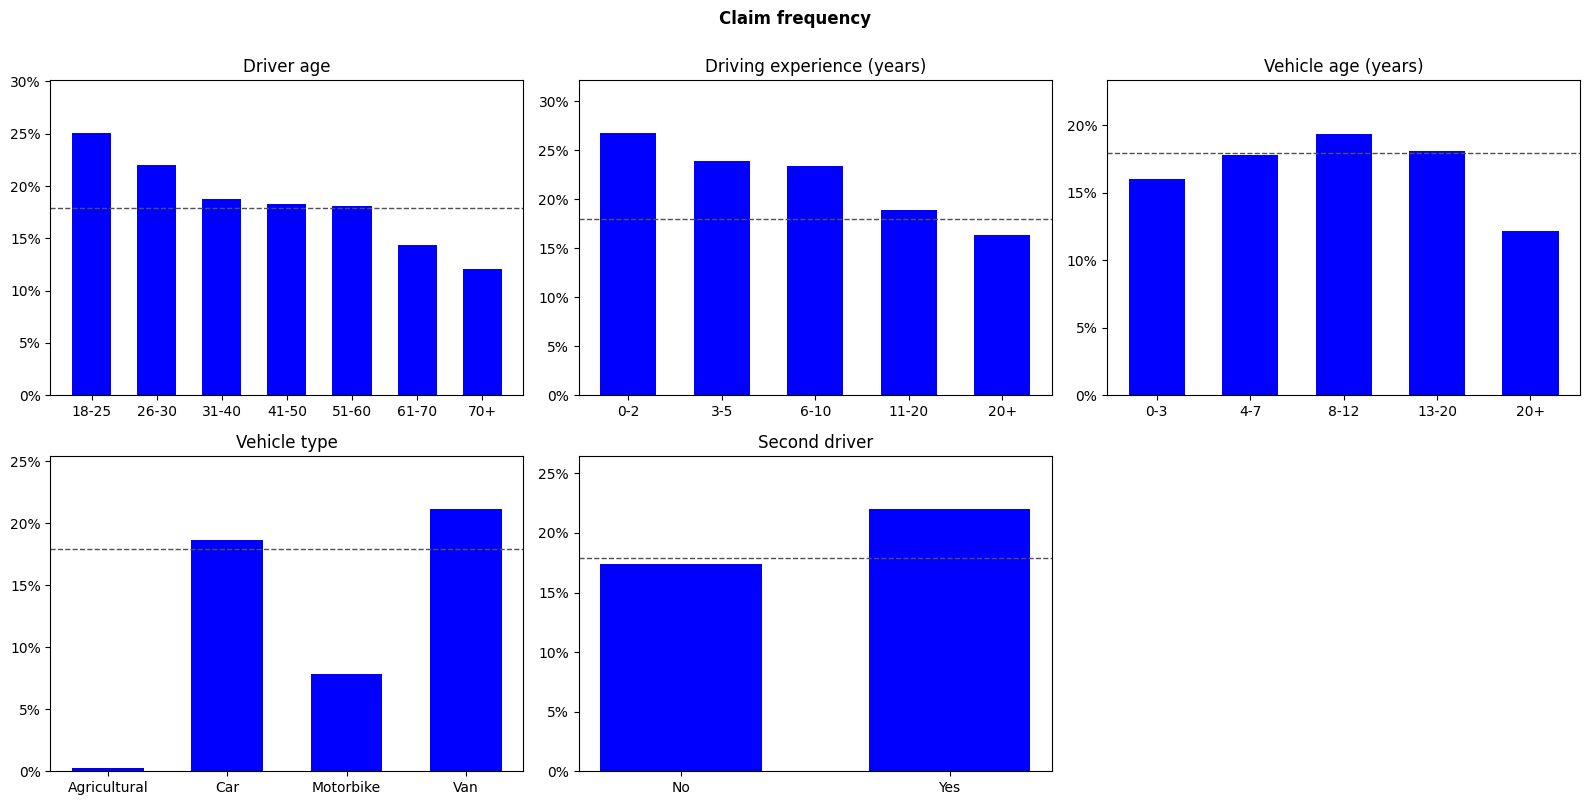

In [26]:
df_clean['Age_group'] = age_bins
df_clean['Vehicle_age_group'] = pd.cut(df_clean.Vehicle_age, [-1, 3, 7, 12, 20, 100], labels=['0-3', '4-7', '8-12', '13-20', '20+'])
df_clean['Experience_group']  = pd.cut(df_clean.Driving_experience, [-1, 2, 5, 10, 20, 100], labels=['0-2', '3-5', '6-10', '11-20', '20+'])

groups = [('Age_group', 'Driver age'), ('Experience_group', 'Driving experience (years)'),
          ('Vehicle_age_group', 'Vehicle age (years)'), ('Vehicle_type', 'Vehicle type'),
          ('Second_driver_label', 'Second driver')]
df_clean['Second_driver_label'] = df_clean.Second_driver.map({0: 'No', 1: 'Yes'})
overall = df_clean.Has_claim.mean()
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (g, t) in zip(axes.ravel(), groups):
    r = df_clean.groupby(g, observed=True).Has_claim.mean()
    ax.bar(r.index.astype(str), r.values, color='blue', width=.6)
    ax.axhline(overall, color='#52514e', ls='--', lw=1)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set(title=t, ylim=(0, max(r.max() * 1.2, overall * 1.3)))

for ax in axes.ravel()[len(groups):]:
    ax.remove()

fig.suptitle('Claim frequency' , fontweight='bold', y=1.0)
plt.tight_layout()
plt.show()

Young and inexperienced drivers claim most (≈ 25–27% vs 12% for drivers over 70), vans claim more than cars and motorbikes (21% vs 19% and 8%), and policies with a second driver claim more (22% vs 17%).

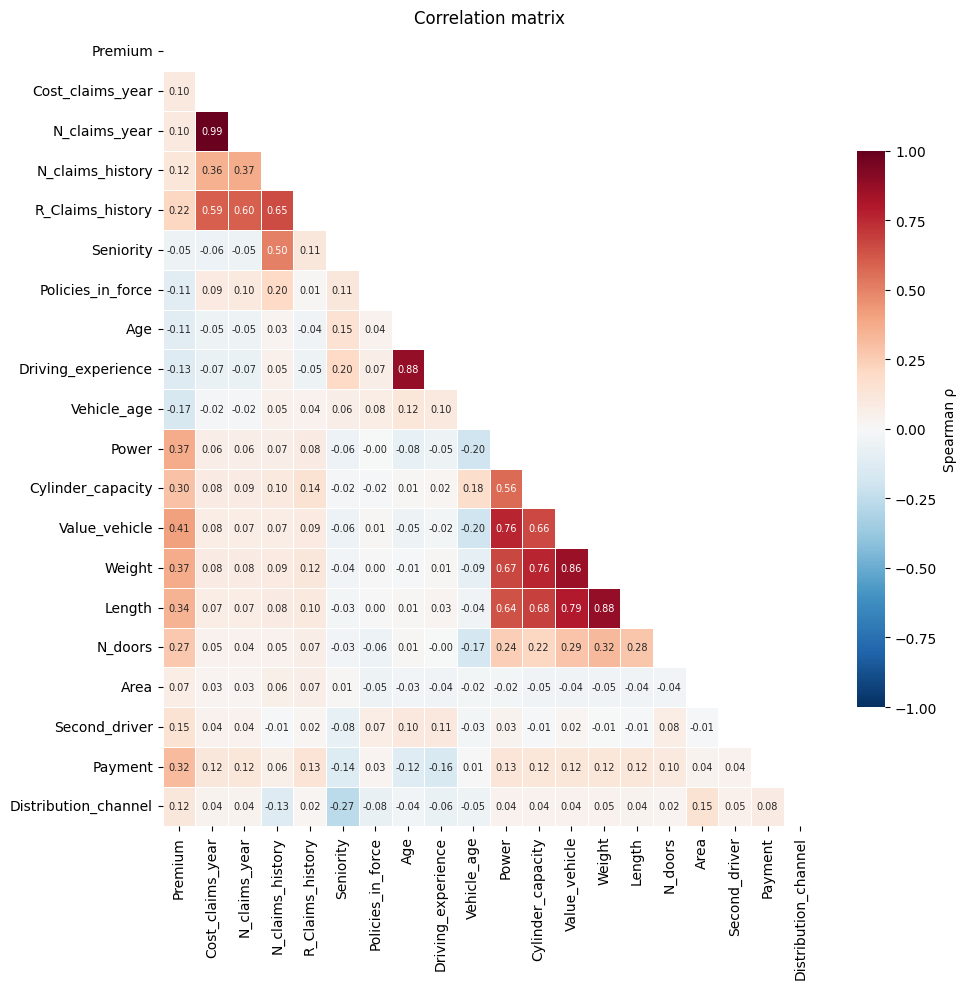

In [27]:
corr_cols = ['Premium', 'Cost_claims_year', 'N_claims_year', 'N_claims_history', 'R_Claims_history',
             'Seniority', 'Policies_in_force', 'Age', 'Driving_experience', 'Vehicle_age',
             'Power', 'Cylinder_capacity', 'Value_vehicle', 'Weight', 'Length', 'N_doors',
             'Area', 'Second_driver', 'Payment', 'Distribution_channel']
corr = df_clean[corr_cols].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 10))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f',
            annot_kws={'size': 7}, linewidths=.5, cbar_kws={'shrink': .7, 'label': 'Spearman ρ'})
plt.title('Correlation matrix'); plt.tight_layout(); plt.show()

Premium is mainly linked to vehicle characteristics (value, power, weight), while several features are almost duplicates (claim cost & count 0.99, weight & length 0.88, age & experience 0.88).

## Modeling: Premium Prediction (ANN)

### 1. Features and target

In [28]:
#numerical features
num_cols = ['Seniority', 'Policies_in_force', 'Max_policies', 'Max_products',
            'N_claims_history', 'R_Claims_history', 'Power', 'Cylinder_capacity',
            'Value_vehicle', 'N_doors', 'Length', 'Weight',
            'Age', 'Driving_experience', 'Licence_age', 'Vehicle_age', 'Contract_years',
            'Length_missing', 'Power_missing']

#categorical features
cat_cols = ['Distribution_channel', 'Payment', 'Vehicle_type', 'Area', 'Second_driver', 'Type_fuel']

#features
X = df_clean[num_cols + cat_cols]
X = pd.get_dummies(X, columns=cat_cols)

#target: log of premium (to reduce skewness)
y = np.log1p(df_clean['Premium'])

print(X.shape, y.shape)

(93401, 34) (93401,)


### 2. Train / Validation / Test split

In [29]:
#split customers (not rows) so the same customer is not in train and test
ids = df_clean['ID'].unique()
train_ids, temp_ids = train_test_split(ids, test_size=0.30, random_state=42)
val_ids, test_ids = train_test_split(temp_ids, test_size=0.50, random_state=42)

#get the rows of each group
train_rows = df_clean['ID'].isin(train_ids)
val_rows = df_clean['ID'].isin(val_ids)
test_rows = df_clean['ID'].isin(test_ids)

X_train, y_train = X[train_rows], y[train_rows]
X_val, y_val = X[val_rows], y[val_rows]
X_test, y_test = X[test_rows], y[test_rows]

print("Train:", X_train.shape, " Validation:", X_val.shape, " Test:", X_test.shape)

Train: (65363, 34)  Validation: (14027, 34)  Test: (14011, 34)


- each customer (ID) has multiple rows one for each year with almost the same data and premium.
- if we split by rows the same customer could appear in both train and test so the model would just remember them (data leakage).
- so we split by customer ID (70% train, 15% validation, 15% test) and all rows of a customer stay in the same set.

### 3. Feature scaling

In [30]:
#scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype('float32')
X_val = scaler.transform(X_val).astype('float32')
X_test = scaler.transform(X_test).astype('float32')

n_inputs = X_train.shape[1]
print("Number of inputs:", n_inputs)

Number of inputs: 34


### 4. Baseline model

In [31]:
#baseline ANN
def build_baseline_model():
    model = keras.Sequential([
        keras.layers.Dense(128, activation='relu', input_shape=(n_inputs,)),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dense(1)   #one output: the premium
    ])
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
                loss='mse', metrics=['mae'])
    return model

baseline_model = build_baseline_model()
history = baseline_model.fit(X_train, y_train, epochs=30, batch_size=256,
                             validation_data=(X_val, y_val))

c:\Users\aleen\miniconda3\envs\crewAI\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.5787 - mae: 0.3544 - val_loss: 0.0635 - val_mae: 0.1890
Epoch 2/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0603 - mae: 0.1837 - val_loss: 0.0601 - val_mae: 0.1832
Epoch 3/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0581 - mae: 0.1802 - val_loss: 0.0596 - val_mae: 0.1826
Epoch 4/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0566 - mae: 0.1777 - val_loss: 0.0584 - val_mae: 0.1817
Epoch 5/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0558 - mae: 0.1765 - val_loss: 0.0575 - val_mae: 0.1796
Epoch 6/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0551 - mae: 0.1753 - val_loss: 0.0581 - val_mae: 0.1813
Epoch 7/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0547 - mae: 0.1748 - val_loss: 0.0577 - val_mae: 0.1802
Epoch 8/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0542 - mae: 0.1739 - val_loss: 0.0566 - val_mae: 0.1776
Epoch 9/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - lo

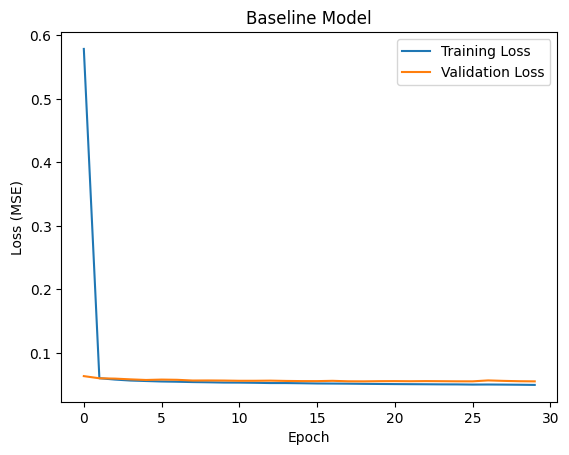

In [ ]:
#plot training vs validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Baseline Model')
plt.legend()
plt.show()

- The first epoch has a high loss because the weights start random then it drops quickly.
- Training and validation loss stay very close so the baseline shows only slight overfitting.

### 5. Optimizer comparison

In [33]:
# Same model, different optimizer
def build_model(optimizer):
    model = keras.Sequential([
        keras.layers.Dense(128, activation='relu', input_shape=(n_inputs,)),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dense(1)
    ])
    model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])
    return model

optimizers = {
    "SGD": keras.optimizers.SGD(learning_rate=0.01),
    "SGD Momentum": keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "RMSProp": keras.optimizers.RMSprop(learning_rate=0.001),
    "Adam": keras.optimizers.Adam(learning_rate=0.001)
}

results = {}
for name, opt in optimizers.items():
    print(f"\nTraining with {name}")
    model = build_model(opt)
    model.fit(X_train, y_train, epochs=10, batch_size=256, verbose=0)
    loss, mae = model.evaluate(X_val, y_val, verbose=0)
    results[name] = mae
    print(f"{name} MAE: {mae:.4f}")

results


Training with SGD


c:\Users\aleen\miniconda3\envs\crewAI\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


SGD MAE: 0.2036

Training with SGD Momentum


c:\Users\aleen\miniconda3\envs\crewAI\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


SGD Momentum MAE: 0.1774

Training with RMSProp


c:\Users\aleen\miniconda3\envs\crewAI\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


RMSProp MAE: 0.2066

Training with Adam


c:\Users\aleen\miniconda3\envs\crewAI\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Adam MAE: 0.1836


{'SGD': 0.2036292403936386,
 'SGD Momentum': 0.1774255782365799,
 'RMSProp': 0.2066303938627243,
 'Adam': 0.18357057869434357}

- SGD with Momentum gave the lowest validation MAE (0.177) followed by Adam (0.183) SGD (0.203) and RMSProp (0.206).
- Momentum clearly improved plain SGD so we use SGD Momentum in the next steps.

### 6. Learning rate tuning

In [34]:
#try different learning rates with SGD Momentum
learning_rates = [0.1, 0.01, 0.001, 0.0001]

for lr in learning_rates:
    print(f"\nTraining with LR = {lr}")
    model = build_model(keras.optimizers.SGD(learning_rate=lr, momentum=0.9))
    model.fit(X_train, y_train, epochs=10, batch_size=256, verbose=0)
    loss, mae = model.evaluate(X_val, y_val, verbose=0)
    print(f"LR {lr} → MAE: {mae:.4f}")


Training with LR = 0.1


c:\Users\aleen\miniconda3\envs\crewAI\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LR 0.1 → MAE: 0.2636

Training with LR = 0.01


c:\Users\aleen\miniconda3\envs\crewAI\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LR 0.01 → MAE: 0.1778

Training with LR = 0.001


c:\Users\aleen\miniconda3\envs\crewAI\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LR 0.001 → MAE: 0.1934

Training with LR = 0.0001


c:\Users\aleen\miniconda3\envs\crewAI\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LR 0.0001 → MAE: 0.2902


### 7. Regularization

#### L2

In [35]:
#L2 regularization: penalize large weights
def build_l2_model():
    model = keras.Sequential([
        keras.layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001),
                           input_shape=(n_inputs,)),
        keras.layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
        keras.layers.Dense(1)
    ])
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
                  loss='mse', metrics=['mae'])
    return model

l2_model = build_l2_model()
history_l2 = l2_model.fit(X_train, y_train, epochs=30, batch_size=256,
                          validation_data=(X_val, y_val))

Epoch 1/30


c:\Users\aleen\miniconda3\envs\crewAI\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


256/256 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.5923 - mae: 0.3427 - val_loss: 0.1931 - val_mae: 0.1934
Epoch 2/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.1803 - mae: 0.1830 - val_loss: 0.1736 - val_mae: 0.1824
Epoch 3/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1652 - mae: 0.1782 - val_loss: 0.1607 - val_mae: 0.1803
Epoch 4/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1534 - mae: 0.1760 - val_loss: 0.1495 - val_mae: 0.1779
Epoch 5/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1430 - mae: 0.1746 - val_loss: 0.1399 - val_mae: 0.1771
Epoch 6/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1340 - mae: 0.1736 - val_loss: 0.1314 - val_mae: 0.1762
Epoch 7/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1259 - mae: 0.1727 - val_loss: 0.1239 - val_mae: 0.1760
Epoch 8/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1187 - mae: 0.1722 - val_loss: 0.1171 - val_mae: 0.1752
Epoch 9/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1123 

- L2 slightly improved the validation MAE (0.171 vs 0.176 for the baseline).
- The gap between training and validation MAE became smaller (0.004 vs 0.010) which means less overfitting.

#### Dropout

In [36]:
#dropout: randomly turn off 20% of neurons during training
def build_dropout_model():
    model = keras.Sequential([
        keras.layers.Dense(128, activation='relu', input_shape=(n_inputs,)),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(1)
    ])
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
                  loss='mse', metrics=['mae'])
    return model

dropout_model = build_dropout_model()
history_dropout = dropout_model.fit(X_train, y_train, epochs=30, batch_size=256,
                                    validation_data=(X_val, y_val))

Epoch 1/30


c:\Users\aleen\miniconda3\envs\crewAI\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


256/256 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.6125 - mae: 0.4090 - val_loss: 0.0662 - val_mae: 0.1926
Epoch 2/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0751 - mae: 0.2086 - val_loss: 0.0623 - val_mae: 0.1860
Epoch 3/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.0693 - mae: 0.1988 - val_loss: 0.0623 - val_mae: 0.1860
Epoch 4/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 13s 49ms/step - loss: 0.0667 - mae: 0.1942 - val_loss: 0.0599 - val_mae: 0.1822
Epoch 5/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 40s 126ms/step - loss: 0.0650 - mae: 0.1917 - val_loss: 0.0589 - val_mae: 0.1813
Epoch 6/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 43s 121ms/step - loss: 0.0648 - mae: 0.1911 - val_loss: 0.0593 - val_mae: 0.1819
Epoch 7/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 82s 318ms/step - loss: 0.0639 - mae: 0.1900 - val_loss: 0.0591 - val_mae: 0.1814
Epoch 8/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0638 - mae: 0.1896 - val_loss: 0.0576 - val_mae: 0.1796
Epoch 9/30
256/256 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step -

- With Dropout the validation MAE (0.177) is lower than the training MAE (0.183) so there is no overfitting.
- However it did not improve the validation MAE compared to the baseline (0.176).
- L2 is still the best so far.

#### Early Stopping

In [37]:
#early stopping: stop when val_loss stops improving
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

es_model = build_baseline_model()
history_es = es_model.fit(X_train, y_train, epochs=100, batch_size=256,
                          validation_data=(X_val, y_val), callbacks=[early_stop])

print("Stopped at epoch:", len(history_es.history['loss']))

Epoch 1/100


c:\Users\aleen\miniconda3\envs\crewAI\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.5707 - mae: 0.3561 - val_loss: 0.0637 - val_mae: 0.1901
Epoch 2/100
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0604 - mae: 0.1840 - val_loss: 0.0608 - val_mae: 0.1861
Epoch 3/100
256/256 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0577 - mae: 0.1799 - val_loss: 0.0585 - val_mae: 0.1816
Epoch 4/100
256/256 ━━━━━━━━━━━━━━━━━━━━ 28s 82ms/step - loss: 0.0564 - mae: 0.1776 - val_loss: 0.0577 - val_mae: 0.1801
Epoch 5/100
256/256 ━━━━━━━━━━━━━━━━━━━━ 31s 117ms/step - loss: 0.0556 - mae: 0.1765 - val_loss: 0.0579 - val_mae: 0.1812
Epoch 6/100
256/256 ━━━━━━━━━━━━━━━━━━━━ 40s 156ms/step - loss: 0.0550 - mae: 0.1754 - val_loss: 0.0579 - val_mae: 0.1800
Epoch 7/100
256/256 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0545 - mae: 0.1747 - val_loss: 0.0568 - val_mae: 0.1788
Epoch 8/100
256/256 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.0540 - mae: 0.1737 - val_loss: 0.0565 - val_mae: 0.1783
Epoch 9/100
256/256 ━━━━━━━━━━━━━━━━━━━━ 27s 106m

- Early Stopping stopped the training at epoch 30.
- The validation MAE (0.175) was almost the same as the baseline (0.176).

#### L2 + Dropout + Early Stopping

In [38]:
#combine L2 + Dropout + Early Stopping
def build_final_model(l2=0.001, dropout=0.1, lr=0.01):
    model = keras.Sequential([
        keras.layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(l2),
                           input_shape=(n_inputs,)),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(l2)),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(1)
    ])
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=lr, momentum=0.9),
                  loss='mse', metrics=['mae'])
    return model

#more patience so it does not stop too early
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

final_model = build_final_model()
history_final = final_model.fit(X_train, y_train, epochs=100, batch_size=256,
                                validation_data=(X_val, y_val), callbacks=[early_stop])

print("Stopped at epoch:", len(history_final.history['loss']))

c:\Users\aleen\miniconda3\envs\crewAI\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
256/256 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.7448 - mae: 0.3951 - val_loss: 0.1949 - val_mae: 0.1890
Epoch 2/100
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.1962 - mae: 0.2026 - val_loss: 0.1809 - val_mae: 0.1870
Epoch 3/100
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.1793 - mae: 0.1951 - val_loss: 0.1664 - val_mae: 0.1825
Epoch 4/100
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1658 - mae: 0.1914 - val_loss: 0.1559 - val_mae: 0.1824
Epoch 5/100
256/256 ━━━━━━━━━━━━━━━━━━━━ 37s 144ms/step - loss: 0.1548 - mae: 0.1896 - val_loss: 0.1453 - val_mae: 0.1806
Epoch 6/100
256/256 ━━━━━━━━━━━━━━━━━━━━ 17s 50ms/step - loss: 0.1449 - mae: 0.1882 - val_loss: 0.1362 - val_mae: 0.1796
Epoch 7/100
256/256 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - loss: 0.1354 - mae: 0.1854 - val_loss: 0.1287 - val_mae: 0.1793
Epoch 8/100
256/256 ━━━━━━━━━━━━━━━━━━━━ 38s 95ms/step - loss: 0.1273 - mae: 0.1838 - val_loss: 0.1207 - val_mae: 0.1775
Epoch 9/100
256/256 ━━━━━━━━━━━━━━━━━━━━

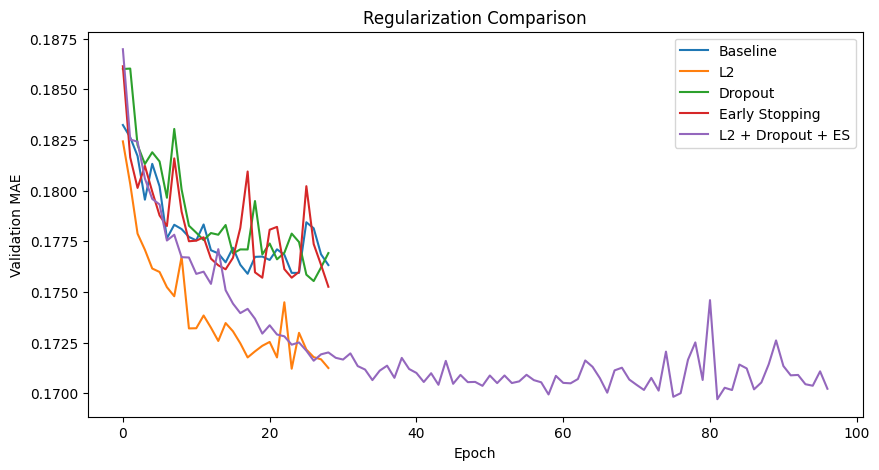

Baseline best val MAE: 0.1759
L2 best val MAE: 0.1712
Dropout best val MAE: 0.1755
Early Stopping best val MAE: 0.1753
L2 + Dropout + ES best val MAE: 0.1697


In [39]:
#compare validation MAE of all models
plt.figure(figsize=(10, 5))
plt.plot(history.history['val_mae'][1:], label='Baseline')
plt.plot(history_l2.history['val_mae'][1:], label='L2')
plt.plot(history_dropout.history['val_mae'][1:], label='Dropout')
plt.plot(history_es.history['val_mae'][1:], label='Early Stopping')
plt.plot(history_final.history['val_mae'][1:], label='L2 + Dropout + ES')
plt.xlabel('Epoch')
plt.ylabel('Validation MAE')
plt.title('Regularization Comparison')
plt.legend()
plt.show()

# Best validation MAE for each model
for name, h in [('Baseline', history), ('L2', history_l2), ('Dropout', history_dropout),
                ('Early Stopping', history_es), ('L2 + Dropout + ES', history_final)]:
    print(name, "best val MAE:", round(min(h.history['val_mae']), 4))

### 8. Hyperparameter tuning (Keras Tuner)

In [40]:
#let Keras Tuner try different settings
def model_builder(hp):
    hp_units = hp.Int("units", min_value=64, max_value=256, step=64)
    hp_layers = hp.Int("layers", min_value=1, max_value=3)
    hp_dropout = hp.Choice("dropout", [0.0, 0.1, 0.2])
    hp_l2 = hp.Choice("l2", [0.0001, 0.001, 0.01])
    hp_lr = hp.Choice("learning_rate", [0.01, 0.001])

    model = keras.Sequential()
    model.add(keras.layers.Input(shape=(n_inputs,)))
    for i in range(hp_layers):
        model.add(keras.layers.Dense(hp_units, activation='relu',
                                     kernel_regularizer=regularizers.l2(hp_l2)))
        model.add(keras.layers.Dropout(hp_dropout))
    model.add(keras.layers.Dense(1))

    model.compile(optimizer=keras.optimizers.SGD(learning_rate=hp_lr, momentum=0.9),
                  loss='mse', metrics=['mae'])
    return model

tuner = kt.RandomSearch(
    model_builder,
    objective="val_mae",
    max_trials=10,
    directory="my_tuning",
    project_name="premium_model_v2"
)

tuner.search(X_train, y_train, epochs=50, batch_size=256,
             validation_data=(X_val, y_val), callbacks=[early_stop])

best_hp = tuner.get_best_hyperparameters(1)[0]
print(best_hp.values)

Reloading Tuner from my_tuning\premium_model_v2\tuner0.json
{'units': 128, 'layers': 3, 'dropout': 0.0, 'l2': 0.001, 'learning_rate': 0.01}


- Keras Tuner tried 10 random combinations. The best one was 3 layers of 128 units, no Dropout, L2 = 0.001 and learning rate = 0.01 (val MAE = 0.174).
- It confirmed our choices of L2 = 0.001 and learning rate = 0.01 and that Dropout does not help on this data.
- However it did not beat our combined model (val MAE = 0.1697) which trained longer so we keep the combined model as our final model.

### 9. Final evaluation on test set

In [41]:
#predict on test set and convert back from log to euros
pred = np.expm1(final_model.predict(X_test).ravel())
actual = np.expm1(y_test)

print("ANN (final model)")
print("MAE :", round(mean_absolute_error(actual, pred), 2), "EUR")
print("RMSE:", round(np.sqrt(mean_squared_error(actual, pred)), 2), "EUR")
print("R2  :", round(r2_score(actual, pred), 3))

# Compare with Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_pred = np.expm1(lr_model.predict(X_test))

print("\nLinear Regression")
print("MAE :", round(mean_absolute_error(actual, lr_pred), 2), "EUR")
print("RMSE:", round(np.sqrt(mean_squared_error(actual, lr_pred)), 2), "EUR")
print("R2  :", round(r2_score(actual, lr_pred), 3))

438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
ANN (final model)
MAE : 48.47 EUR
RMSE: 65.52 EUR
R2  : 0.456

Linear Regression
MAE : 51.66 EUR
RMSE: 69.92 EUR
R2  : 0.38


In [42]:
#compare train vs test to check overfitting
train_pred = np.expm1(final_model.predict(X_train).ravel())
train_actual = np.expm1(y_train)

print("Train MAE:", round(mean_absolute_error(train_actual, train_pred), 2), "EUR")
print("Test MAE :", round(mean_absolute_error(actual, pred), 2), "EUR")
print("Train R2 :", round(r2_score(train_actual, train_pred), 3))
print("Test R2  :", round(r2_score(actual, pred), 3))

2043/2043 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
Train MAE: 47.84 EUR
Test MAE : 48.47 EUR
Train R2 : 0.495
Test R2  : 0.456


- ANN test MAE = 48.47 EUR, R2 = 0.456, which is better than Linear Regression (51.66 EUR, R2 = 0.38).
- Train and test MAE are very close (47.84 vs 48.47) so there is no overfitting.

### 10. Save and load the model

In [43]:
import os
import joblib

#create a folder for the saved files
os.makedirs("models", exist_ok=True)

#save the model, scaler and column names
final_model.save("models/premium_model.keras")
joblib.dump(scaler, "models/premium_scaler.joblib")
joblib.dump(list(X.columns), "models/premium_columns.joblib")

#load them back
loaded_model = keras.models.load_model("models/premium_model.keras")
loaded_scaler = joblib.load("models/premium_scaler.joblib")
loaded_columns = joblib.load("models/premium_columns.joblib")

#check that the loaded model gives the same result
loaded_pred = np.expm1(loaded_model.predict(X_test).ravel())
print("Test MAE (loaded model):", round(mean_absolute_error(actual, loaded_pred), 2), "EUR")

438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Test MAE (loaded model): 48.47 EUR


### 11. Inference

In [44]:
#predict the premium for a new customer
def predict_premium(customer):
    row = pd.DataFrame([customer])
    row = pd.get_dummies(row, columns=cat_cols)
    row = row.reindex(columns=loaded_columns, fill_value=0)   # same columns as training
    row = loaded_scaler.transform(row).astype('float32')
    pred = loaded_model.predict(row, verbose=0)[0][0]
    return round(float(np.expm1(pred)), 2)

#example: young driver with little experience and a powerful car
customer_1 = {
    'Seniority': 1, 'Policies_in_force': 1, 'Max_policies': 1, 'Max_products': 1,
    'N_claims_history': 2, 'R_Claims_history': 1.0, 'Power': 180, 'Cylinder_capacity': 2500,
    'Value_vehicle': 35000, 'N_doors': 3, 'Length': 4.4, 'Weight': 1450,
    'Age': 22, 'Driving_experience': 2, 'Licence_age': 20, 'Vehicle_age': 2, 'Contract_years': 1,
    'Length_missing': 0, 'Power_missing': 0,
    'Distribution_channel': 0, 'Payment': 0, 'Vehicle_type': 'Car', 'Area': 1,
    'Second_driver': 0, 'Type_fuel': 'P'
}

#example: older experienced driver with a small old car
customer_2 = {
    'Seniority': 10, 'Policies_in_force': 2, 'Max_policies': 2, 'Max_products': 2,
    'N_claims_history': 0, 'R_Claims_history': 0.0, 'Power': 75, 'Cylinder_capacity': 1200,
    'Value_vehicle': 9000, 'N_doors': 5, 'Length': 3.9, 'Weight': 1000,
    'Age': 50, 'Driving_experience': 30, 'Licence_age': 20, 'Vehicle_age': 12, 'Contract_years': 8,
    'Length_missing': 0, 'Power_missing': 0,
    'Distribution_channel': 0, 'Payment': 0, 'Vehicle_type': 'Car', 'Area': 0,
    'Second_driver': 0, 'Type_fuel': 'D'
}

print("Customer 1 premium:", predict_premium(customer_1), "EUR")
print("Customer 2 premium:", predict_premium(customer_2), "EUR")

Customer 1 premium: 607.41 EUR
Customer 2 premium: 231.99 EUR
